# ขั้นที่ 4: งานที่ 1 — ทำนายชื่อวิทยาศาสตร์และยุคที่ขาดหาย

| เป้าหมาย | ระดับ | label | วัดผล |
|---|---|---|---|
| **สกุล → ชนิด** | ตัวอย่าง (ทะเบียน) | ชื่อสกุลจริงจาก `sci_name` (ตัดชื่อไม่เป็นทางการ เช่น Sauropod) | accuracy, top-3, macro-F1; ชนิด = P(สกุล) × P(ชนิด \| สกุล) |
| **ยุค** | แหล่ง | train: ยุคที่ ทธ. บันทึก + ค่าเติมจาก notebook 05 ระดับ high/medium ที่มี PBDB รองรับ | **วัดเฉพาะยุคที่ ทธ. บันทึก**; accuracy, top-3, คลาดไม่เกิน 1 ยุค (`within1`) |

**feature**: ข้อมูลของตัวอย่าง (ชื่อสามัญแบบทั่วไป, ประเภท, ส่วนของซาก, ที่ตั้ง) + feature ของแหล่งที่เชื่อม
(พันเจีย, DEM, ธรณีวิทยา, Sentinel-2) + ประเภทซากที่พบในแหล่ง + **embedding จาก CNN ของงานที่ 2** (16 องค์ประกอบหลักจาก PCA)

**กัน data leak** (ตกลงกันหลังรอบแรก): ตัด feature ที่ได้มา*หลัง*รู้ชื่อวิทยาศาสตร์ หรือเป็นผลจากขั้นตอนเชื่อมข้อมูล
- สกุล: `com_name` → `com_name_generic`, ตัด `dis_name`, `match_level`, `confidence` (รายละเอียดในหัวข้อ 2)
- ยุค: ใช้ feature ของแหล่งอย่างเดียว ตัดประเภทซากในแหล่ง (มาจากทะเบียนตัวอย่าง/คำบรรยายแหล่ง ชุดเดียวกับที่ใช้เติมยุคใน notebook 03–05) และ CNN embedding

**CV 3 แบบ** (fold เดียวกับ notebook 10): `random` (ตัวอย่างแต่ละชิ้นสุ่ม fold), `site_cluster`, `spatial_block`
— ตัวอย่างที่ต้องเติมชื่อส่วนใหญ่อยู่ในแหล่งที่มีตัวอย่างระบุชื่อแล้ว (notebook 07: 86%) ตัวเลข `random` จึงใกล้งานจริงของชื่อวิทยาศาสตร์
ส่วนยุคเป็นคุณสมบัติของแหล่ง ตัวเลข `spatial_block` ใกล้งานจริงกว่า

**รันต่อได้**: ผลทุก (การทดลอง, fold) อยู่ใน `models/task1/`, MLP มี checkpoint ทุก epoch

In [1]:
import sys

sys.path.insert(0, ".")
import model_lib as ml
import feature_lib as fl

import json
import re

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib import font_manager
from sklearn.decomposition import PCA

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 40, "display.width", 180)
INK, MUTED = "#52514e", "#8a8984"
cv_color = {"random": "#bdbcb6", "site_cluster": "#86b6ef", "spatial_block": "#2a78d6"}
ml.seed_everything(42)
OUT = ml.MODELS / "task1"
FINAL = OUT / "final"
FINAL.mkdir(parents=True, exist_ok=True)
T2 = ml.MODELS / "task2" / "final"

## 1. feature ระดับแหล่ง

- feature เดียวกับงานที่ 2 (`all_features.parquet`) ของแหล่ง ทธ.
- **ประเภทซากที่พบในแหล่ง** (17 กลุ่ม, จากตัวอย่าง + คำในชื่อแหล่ง แบบเดียวกับ notebook 10) เป็น flag 0/1
- **embedding จาก CNN ขั้น A ของงานที่ 2** (`bg_bias`) 128 มิติ → PCA 16 มิติ (`cnn_pc0..15`)
  - **ตอนวัดผล (CV)**: fold k ของแบบ CV s ใช้ CNN ของ fold เดียวกันจาก notebook 10 (`A_bg_bias/fold_models/{s}__cnn__f{k}.pt`)
    ซึ่ง train โดยไม่เห็นแหล่งใน fold k และ PCA fit เฉพาะแหล่ง train ของ fold นั้น → แหล่งทดสอบเป็นภาพที่ CNN ไม่เคยเห็นจริง
    (ถ้าใช้ CNN ตัวจริงที่ train ด้วยทุกแหล่ง embedding ของแหล่งทดสอบจะมาจากภาพที่ CNN จำได้แล้ว → ผล CV ดีเกินจริง)
  - **โมเดลตัวจริง**: CNN ตัวจริง + PCA fit ทุกแหล่ง (บันทึก `cnn_pca.joblib` ไว้ใช้ใน notebook 12)

In [2]:
allf = pd.read_parquet(ml.FEAT / "all_features.parquet").merge(pd.read_parquet(ml.FEAT / "folds.parquet"), on="point_id")
fg = json.loads((ml.FEAT / "feature_groups.json").read_text(encoding="utf-8"))
meta2 = json.loads((T2 / "final_meta.json").read_text(encoding="utf-8"))
CAT_SITE = ["pg_sw18_plate", "pg_me21_plate", "pg_me21_terrane", "geo_rock_sym", "geo_era_old", "geo_era_young", "geo_rock_kind"]
for c in CAT_SITE + ["oc_nearest_rock"]:
    allf[c] = allf[c].astype(str)
SITE_NUM, SITE_CAT = meta2["features"]["num"], [c for c in meta2["features"]["cat"] if c in CAT_SITE]

sites = allf[allf.source.eq("dmr_site")].copy()
sites["oid"] = sites.point_id.str[4:].astype(int)

spec = pd.read_csv(ml.DATA / "processed" / "fossil_list_final.csv", dtype={"fossil_id": str, "site_OBJECTID": "Int64"},
                   encoding="utf-8-sig", low_memory=False)
hm = spec[spec.confidence.isin(["high", "medium"])].copy()
hm["cls"] = [fl.specimen_classes(t, c) for t, c in zip(hm.f_type, hm.com_name)]
hm["sid"] = hm.tied_site_ids.str.split(";")
hm = hm.explode("sid")
from_spec = hm.groupby(hm.sid.astype(float).astype(int)).cls.agg(lambda s: set().union(*s))
raw = gpd.read_file(ml.DATA / "dmr_fossil_sites" / "fossil_sites.geojson")[["OBJECTID", "NAME_TH", "FOS_DES_TH", "PERIODFROM"]]
raw["OBJECTID"] = raw.OBJECTID.astype(int)
from_text = {o: fl.classes_of(f"{n or ''} {d or ''}") for o, n, d in zip(raw.OBJECTID, raw.NAME_TH, raw.FOS_DES_TH)}
TYPE_COLS = [f"type_{c}" for c in fl.FOSSIL_CLASSES]
for c in fl.FOSSIL_CLASSES:
    sites[f"type_{c}"] = [int(c in (from_spec.get(o, set()) | from_text.get(o, set()))) for o in sites.oid]

patches, ok = ml.load_patches(sites.point_id.values, ml.FEAT / "s2" / "patches")
EMB_COLS = [f"cnn_pc{i}" for i in range(16)]


def site_embedding(cnn_path, fit_mask, pca_path=None):
    # CNN embedding ของทุกแหล่ง -> PCA ที่ fit เฉพาะแหล่ง fit_mask (แหล่งไม่มี patch = ค่าว่าง)
    # pca_path: ใช้ PCA เดิมเฉพาะเมื่อ fingerprint (ไฟล์ CNN + patch + แหล่งที่ fit) ตรง (เก็บใน <ไฟล์>.fp)
    emb = ml.embed_bundle(cnn_path, patches)
    fp = ml.fingerprint(ml.file_hash(cnn_path), ml.fingerprint(sites.point_id, patches, ok), fit_mask)
    side = None if pca_path is None else pca_path.with_name(pca_path.name + ".fp")
    if pca_path is not None and pca_path.exists() and (side.read_text().strip() if side.exists() else None) == fp:
        pca = ml.joblib.load(pca_path)
    elif pca_path is not None and pca_path.exists() and not side.exists() and not ml.VERIFY_CACHE:
        pca = ml.joblib.load(pca_path)                                   # ไฟล์รุ่นก่อนมี fingerprint
    else:
        pca = PCA(n_components=16, random_state=0).fit(emb[fit_mask & ok])
        if pca_path is not None and pca_path.exists() and not side.exists():   # ตรวจไฟล์รุ่นก่อน: เทียบกับ PCA ที่ fit ใหม่
            old = ml.joblib.load(pca_path)
            same = np.allclose(old.transform(emb[ok]), pca.transform(emb[ok]), atol=1e-3)
            print(f"[cache] {pca_path.name}: {'ตรงกับที่ fit ใหม่' if same else 'ไม่ตรง -> แทนที่'}")
            pca = old if same else pca
        if pca_path is not None:
            ml.joblib.dump(pca, pca_path)
            side.write_text(fp)
    E = pd.DataFrame(pca.transform(emb), columns=EMB_COLS, index=sites.oid.values)
    E[~ok] = np.nan
    return E, pca


# โมเดลตัวจริง: CNN ตัวจริง + PCA ทุกแหล่ง
pca_path = FINAL / "cnn_pca.joblib"
E_final, pca = site_embedding(T2 / meta2["stage_A"]["bg_bias"]["cnn"], np.ones(len(sites), bool), pca_path)
sites[EMB_COLS] = E_final.values
sites[["point_id", "oid"] + TYPE_COLS + EMB_COLS].to_parquet(ml.FEAT / "site_task1_features.parquet", index=False)   # ใช้ใน notebook 12

# CV: embedding ต่อ (แบบ CV, fold) จาก CNN ของ fold นั้น (cache ไว้ใน models/task1/emb/)
A_FOLD = ml.MODELS / "task2" / "A_bg_bias" / "fold_models"
EMB_DIR = OUT / "emb"
EMB_DIR.mkdir(parents=True, exist_ok=True)
EMB = {}
PATCH_FP = ml.fingerprint(sites.point_id, patches, ok)
for cv in ml.tqdm_auto()(ml.CV_SCHEMES, desc="embedding ต่อ fold"):
    for k in range(ml.N_FOLDS):
        # cache ใช้ซ้ำเฉพาะเมื่อ CNN ของ fold, patch และแหล่งที่ fit PCA ตรงกับปัจจุบัน (ค่าบน MPS ต่างได้ ≤ 1e-3)
        cnn_k, fit_k = A_FOLD / f"{cv}__cnn__f{k}.pt", sites[f"fold_{cv}"].values != k
        EMB[cv, k] = ml.cached_frame(EMB_DIR / f"{cv}__f{k}.parquet", ml.fingerprint(ml.file_hash(cnn_k), PATCH_FP, fit_k),
                                     lambda cnn_k=cnn_k, fit_k=fit_k: site_embedding(cnn_k, fit_k)[0], index=True, atol=1e-3)


def with_emb(df, cv, k, key="oid"):
    # แทน cnn_pc* ด้วย embedding ของ (cv, fold k); key = คอลัมน์รหัสแหล่ง
    return df.drop(columns=EMB_COLS).join(EMB[cv, k], on=key)


print(f"แหล่ง {len(sites)} | มี patch {ok.mean():.0%} | PCA ตัวจริงอธิบายความแปรปรวน {pca.explained_variance_ratio_.sum():.0%} | "
      f"embedding ต่อ fold {len(EMB)} ชุด")

embedding ต่อ fold: 100%|██████████| 3/3 [00:00<00:00, 40.07it/s]


แหล่ง 518 | มี patch 100% | PCA ตัวจริงอธิบายความแปรปรวน 99% | embedding ต่อ fold 15 ชุด


## 2. สกุล (ระดับตัวอย่าง)

- สกุลจาก `sci_name` ด้วย `fl.parse_taxon` (ตัด `N/A (...)`, ชื่อไม่เป็นทางการ, ชื่อระดับวงศ์ขึ้นไป)
- สกุลที่มีตัวอย่าง < 5 ชิ้นรวมเป็น `อื่น ๆ`
- ตัวอย่างที่ไม่ได้เชื่อมแหล่ง: feature ของแหล่งเป็นค่าว่าง (โมเดลต้นไม้รับค่าว่างได้, MLP/kNN เติมด้วยค่ากลาง)
- รันทีละ fold เพื่อให้ `cnn_pc*` ของ fold k มาจาก CNN ของ fold k — ใน `site_cluster` / `spatial_block` แหล่งของตัวอย่างทดสอบ
  ไม่เคยอยู่ใน train ของทั้งโมเดลนี้และ CNN; ใน `random` ตัวอย่างอื่นจากแหล่งเดียวกันอยู่ใน train อยู่แล้วโดยตั้งใจ (จำลองงานเติมชื่อจริง)

**feature ที่ตัด / แปลงเพื่อกัน data leak**

| feature | ปัญหา | ทำอย่างไร |
|---|---|---|
| `com_name` | ตัวอย่างที่ระบุชนิดแล้วมักมีชื่อไทยของ*ชนิดนั้น* (เช่น "จระเข้ภูพอก" = *Siamosuchus*, "นักล่าแห่งภูเวียง" = *Phuwiangvenator*) ตั้งหลังรู้ชื่อวิทยาศาสตร์ — ตัวอย่างที่ต้องเติมชื่อแทบไม่มีชื่อแบบนี้ | `com_name_generic`: ใช้ค่าเดิมเฉพาะชื่อที่ตัวอย่าง*ที่ยังไม่มีชื่อ*ก็ใช้ (ชื่อทั่วไป เช่น "ไดโนเสาร์", "ฉลาม") ไม่งั้นแทนด้วย `f_type` |
| `match_level`, `confidence` | ผลของขั้นเชื่อมตัวอย่างกับแหล่ง (notebook 02) ซึ่งให้คะแนนจากคำใน `com_name` → สะท้อนว่าตัวอย่างถูกระบุชื่อแล้วหรือยัง ไม่ใช่คุณสมบัติของซาก | ตัด |
| `dis_name` | ผู้ค้นพบ/คณะสำรวจ — บางชื่อเป็นนักบรรพชีวินที่ตั้งชื่อชนิด จึงบอก "ได้รับการศึกษาแล้ว" มากกว่าบอกสกุล | ตัด |

ผลรอบแรก (มี feature เหล่านี้) เก็บไว้ที่ `models/task1/genus/` และแสดงเทียบในตาราง เพื่อดูว่าตัวเลขเดิมสูงเกินจริงเท่าไร

In [3]:
spec["taxon"] = spec.sci_name.map(fl.parse_taxon)
spec["genus_true"] = spec.taxon.map(lambda t: t[0] if t else None)
spec["species_true"] = spec.taxon.map(lambda t: t[1] if t else None)
S = spec.merge(sites.drop(columns=["source", "ref_id"]).rename(columns={"oid": "site_OBJECTID"}).assign(
    site_OBJECTID=lambda d: d.site_OBJECTID.astype("Int64")), on="site_OBJECTID", how="left")
S["point_id"] = S.fossil_id

# fold: random = ต่อชิ้น; site_cluster / spatial_block = ตาม fold ของแหล่ง (ไม่มีแหล่ง -> สุ่ม)
rng = np.random.default_rng(42)
S["fold_random"] = rng.integers(0, ml.N_FOLDS, len(S))
for sc in ["site_cluster", "spatial_block"]:
    S[f"fold_{sc}"] = S[f"fold_{sc}"].fillna(pd.Series(rng.integers(0, ml.N_FOLDS, len(S)), index=S.index)).astype(int)

# กัน data leak: com_name ใช้ได้เฉพาะ "ชื่อทั่วไป" ที่ตัวอย่างที่ยังไม่มีชื่อวิทยาศาสตร์ก็ใช้ (ไม่ใช้ label)
COM_VOCAB = sorted(set(S.loc[S.genus_true.isna(), "com_name"].dropna()))
S["com_name_generic"] = S.com_name.where(S.com_name.isin(COM_VOCAB), S.f_type)
LEAKY = ["com_name", "dis_name", "match_level", "confidence"]
SPEC_CAT = ["com_name_generic", "f_type", "f_group", "f_part", "province", "district"]
for c in SPEC_CAT + LEAKY + SITE_CAT:
    S[c] = S[c].astype(str)
S["groups"] = [fl.specimen_classes(t, c) for t, c in zip(S.f_type, S.com_name_generic)]     # กลุ่มซาก (ใช้กับตัวกรองความสอดคล้อง)

named = S.genus_true.notna()
one_genus = S[named].groupby("com_name").genus_true.nunique().pipe(lambda s: s[s == 1].index)
display(pd.DataFrame({
    "มีสกุล (train)": [S[named].com_name.isin(one_genus).mean(), (S[named].com_name != S[named].com_name_generic).mean()],
    "ไม่มีสกุล (ต้องทำนาย)": [S[~named].com_name.isin(one_genus).mean(), (S[~named].com_name != S[~named].com_name_generic).mean()],
}, index=["com_name ที่ชี้สกุลเดียว", "com_name ที่ถูกแทนด้วย f_type"]).style.format("{:.0%}"))
FS1 = {
    "specimen": ([], SPEC_CAT),
    "specimen+site": (SITE_NUM + ["lon", "lat"], SPEC_CAT + SITE_CAT),
    "specimen+site+cnn": (SITE_NUM + ["lon", "lat"] + EMB_COLS, SPEC_CAT + SITE_CAT),
    "all": (SITE_NUM + ["lon", "lat"] + EMB_COLS + TYPE_COLS, SPEC_CAT + SITE_CAT),
}

lab = S[S.genus_true.notna()].reset_index(drop=True)
gc = lab.genus_true.value_counts()
GENERA = sorted(gc[gc >= 5].index) + ["อื่น ๆ"]
lab["genus_cls"] = lab.genus_true.where(lab.genus_true.isin(GENERA), "อื่น ๆ")
YG = lab.genus_cls.map({g: i for i, g in enumerate(GENERA)}).values
print(f"ตัวอย่างที่มีสกุลจริง {len(lab):,} | สกุลทั้งหมด {gc.size} | ใช้เป็นคลาส {len(GENERA) - 1} สกุล + อื่น ๆ "
      f"({(lab.genus_cls == 'อื่น ๆ').mean():.0%} ของตัวอย่าง)")
print(f"ตัวอย่างที่ต้องทำนาย (ไม่มีสกุล): {S.genus_true.isna().sum():,}")

,มีสกุล (train),ไม่มีสกุล (ต้องทำนาย)
com_name ที่ชี้สกุลเดียว,33%,2%
com_name ที่ถูกแทนด้วย f_type,37%,1%


ตัวอย่างที่มีสกุลจริง 3,944 | สกุลทั้งหมด 419 | ใช้เป็นคลาส 131 สกุล + อื่น ๆ (12% ของตัวอย่าง)
ตัวอย่างที่ต้องทำนาย (ไม่มีสกุล): 4,577


In [4]:
regG = ml.Registry(OUT / "genus_v5")            # label สกุลหลังตรวจทาน (ตัดชื่อระดับสูง เช่น Ruminantia, แก้ชื่อสะกดผิด)
ml.set_multiclass(len(GENERA))
ml.MC_CONTEXT.clear()
ml.MC_CONTEXT.update(classes=GENERA, ordinal=None)
G_MODELS = ["prior", "knn_coords", "rf", "lgbm", "xgb", "mlp"]
G_ABL = ["specimen", "specimen+site", "specimen+site+cnn"]

def run_job(reg, d, Y, cv, m, FS, epochs, classes, main="all"):
    # รันทีละ fold: ข้อมูลของ fold k ใช้ cnn_pc* จาก CNN ของ fold k (การทดลองที่ไม่ใช้ cnn_pc* ได้ผลเหมือนรันรวด)
    # main = ชุด feature ของโมเดลหลัก (rf/lgbm/xgb/mlp); "lgbm@<ชุด>" = ablation
    exp, fc = f"{cv}__{m}", f"fold_{cv}"
    kw = dict(task="multiclass", classes=classes, only_folds=None)
    for k in range(ml.N_FOLDS):
        dk, kw["only_folds"] = with_emb(d, cv, k, "site_OBJECTID" if "site_OBJECTID" in d else "oid"), [k]
        if m == "prior":
            ml.run_tabular_cv(reg, exp, dk, np.eye(len(classes))[Y], fc, "prior", ["lat"], [], task="multilabel", classes=classes, only_folds=[k])
        elif m == "knn_coords":
            ml.run_tabular_cv(reg, exp, dk, Y, fc, "knn", ["lon", "lat"], [], **kw)
        elif m == "mlp":
            ml.run_torch_cv(reg, exp, dk, Y, fc, "mlp", num_cols=FS[main][0], cat_cols=FS[main][1], epochs=epochs, **kw)
        elif "@" in m:
            ml.run_tabular_cv(reg, exp, dk, Y, fc, "lgbm", *FS[m.split("@")[1]], **kw)
        else:
            ml.run_tabular_cv(reg, exp, dk, Y, fc, m, *FS[main], **kw)


jobs = [(cv, m) for cv in ml.CV_SCHEMES for m in G_MODELS] + [(cv, f"lgbm@{fs}") for cv in ml.CV_SCHEMES for fs in G_ABL]
for cv, m in ml.tqdm_auto()(jobs, desc="สกุล"):
    run_job(regG, lab, YG, cv, m, FS1, 60, GENERA)

spatial_block__lgbm@specimen+site+cnn:   0%|          | 0/1 [00:00<?, ?it/s]


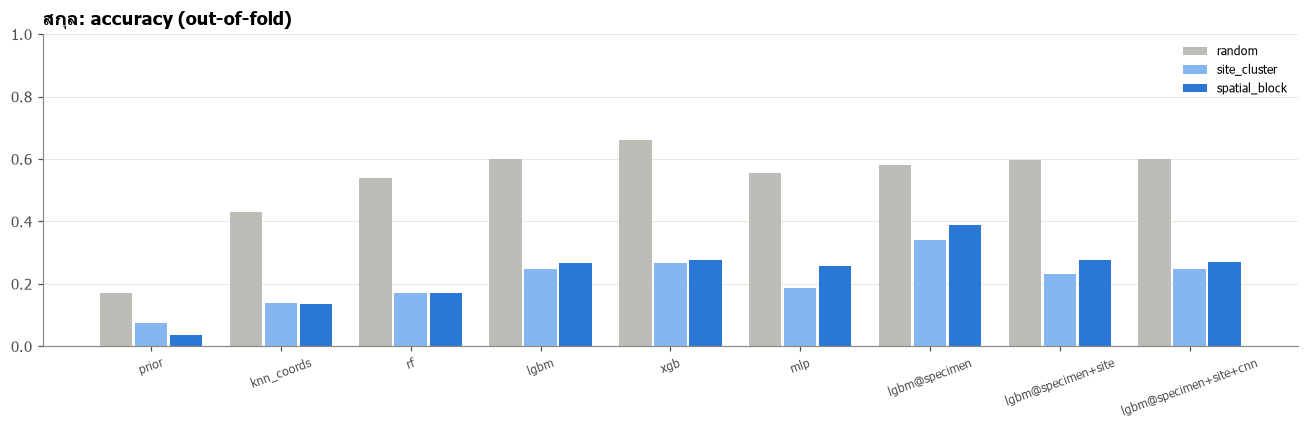

In [5]:
def mc_table(reg, metric, classes, ordinal=None, rows_mask=None):
    # คำนวณใหม่จาก OOF (รองรับ prior ที่บันทึกแบบ multilabel และการกรองแถวที่วัดผล)
    out = {}
    for exp in reg.results().exp.unique():
        o = reg.oof(exp)
        pcols = [c for c in o.columns if c.startswith("p_")]
        y = o.y.values if "y" in o else o[[c for c in o.columns if c.startswith("y_")]].values.argmax(axis=1)
        keep = np.ones(len(o), bool) if rows_mask is None else o.point_id.isin(rows_mask).values
        r = {}
        for k, g in o[keep].groupby("fold"):
            gi = g.index
            r[k] = ml.multiclass_metrics(y[gi], g[pcols].values, classes, ordinal)[metric]
        cv, m = exp.split("__")
        out[(m, cv)] = np.mean(list(r.values()))
    return pd.Series(out).unstack()[ml.CV_SCHEMES]


G_ORDER = G_MODELS + [f"lgbm@{f}" for f in G_ABL]
tG = pd.concat({m: mc_table(regG, m, GENERA).reindex(G_ORDER) for m in ["acc", "top3", "macro_f1"]}, axis=1)
if (OUT / "genus" / "results.parquet").exists():          # รอบแรก (มี com_name / dis_name / match_level / confidence) เพื่อเทียบ
    regG_old = ml.Registry(OUT / "genus")
    old = pd.concat({m: mc_table(regG_old, m, GENERA).reindex(["lgbm", "xgb"]) for m in ["acc", "top3", "macro_f1"]}, axis=1)
    tG = pd.concat([tG, old.rename(lambda s: f"{s} (รอบแรก: มี feature รั่ว)")])
display(tG.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))

fig, ax = plt.subplots(figsize=(12, 4))
t = mc_table(regG, "acc", GENERA).reindex(G_ORDER)
x = np.arange(len(t))
for i, cv in enumerate(ml.CV_SCHEMES):
    ax.bar(x + (i - 1) * 0.27, t[cv], width=0.25, color=cv_color[cv], label=cv)
ax.set_xticks(x, t.index, rotation=20, fontsize=8)
ax.set_ylim(0, 1)
ax.set_title("สกุล: accuracy (out-of-fold)")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout()

### ระบบที่ใช้จริง: สลับโมเดลตามกรณี + ตัวกรองความสอดคล้องทางอนุกรมวิธาน

(ตกลงกันหลังดูผลรอบที่ตัด feature รั่ว)
- **สลับตามกรณี**: ตัวอย่างที่แหล่งมีตัวอย่างระบุสกุลแล้ว (ใน train) → `xgb` (ทุก feature, ดีสุดที่แหล่งเดิม);
  แหล่งใหม่ / ไม่ได้เชื่อมแหล่ง → `lgbm@specimen` (ข้อมูลตัวอย่างอย่างเดียว, ดีสุดที่แหล่งใหม่)
- **ตัวกรอง**: ตัดสกุลที่ตัวอย่างใน train ไม่เคยอยู่กลุ่มซากเดียวกับตัวอย่างนี้ (กลุ่มจาก `f_type` / `com_name_generic`)
  แล้ว normalize ใหม่ — กันการทายข้ามกลุ่ม เช่น "ไดโนเสาร์" → เต่า, "กิ้งก่าและงู" → กวาง; mapping สกุล → กลุ่มสร้างจาก fold train เท่านั้น

In [6]:
labi = lab.set_index("fossil_id")
PC = [f"p_{j}" for j in range(len(GENERA))]


def routed_oof(cv, known_model="xgb", new_model="lgbm@specimen", use_filter=True, route=True):
    # OOF ของระบบจริงต่อ fold: แหล่งที่มีตัวอย่างมีสกุลใน train -> known_model, ไม่งั้น new_model; แล้วกรองด้วยกลุ่มซาก
    a = regG.oof(f"{cv}__{known_model}").set_index("point_id")
    b = regG.oof(f"{cv}__{new_model}").set_index("point_id").loc[a.index]
    out = []
    for k in sorted(a.fold.unique()):
        ids = a.index[a.fold == k]
        tr = labi[labi[f"fold_{cv}"] != k]
        known = ml.route_known_site(labi.loc[ids, "site_OBJECTID"], tr.site_OBJECTID.dropna().astype(int))
        P = np.where(known[:, None], a.loc[ids, PC].values, b.loc[ids, PC].values) if route else a.loc[ids, PC].values
        if use_filter:
            P = ml.consistency_filter(P, GENERA, labi.loc[ids, "groups"], ml.genus_group_map(tr.genus_cls, tr.groups))
        out.append(pd.DataFrame(P, columns=PC, index=ids).assign(fold=k, y=a.loc[ids, "y"].values, known=known))
    return pd.concat(out).rename_axis("point_id").reset_index()


def fold_mean(o, metric):
    return np.mean([ml.multiclass_metrics(g.y.values, g[PC].values, GENERA)[metric] for _, g in o.groupby("fold")])


systems = {"xgb": dict(use_filter=False, route=False), "xgb + ตัวกรอง": dict(route=False),
           "lgbm@specimen": dict(known_model="lgbm@specimen", use_filter=False, route=False),
           "สลับตามกรณี": dict(use_filter=False), "สลับตามกรณี + ตัวกรอง (ใช้จริง)": {}}
ROUTED, rows = {}, []
for cv in ml.CV_SCHEMES:
    for name, kw_ in systems.items():
        o = routed_oof(cv, **kw_)
        if name.endswith("(ใช้จริง)"):
            ROUTED[cv] = o
        rows.append({"ระบบ": name, "cv": cv, "acc": fold_mean(o, "acc"), "top3": fold_mean(o, "top3"),
                     "แหล่งเดิม": o.known.mean()})
tR = pd.DataFrame(rows).pivot(index="ระบบ", columns="cv", values=["acc", "top3"]).reindex(list(systems))
display(tR.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))
print("สัดส่วนตัวอย่างทดสอบที่ส่งไปโมเดลแหล่งเดิม:", {cv: f"{ROUTED[cv].known.mean():.0%}" for cv in ml.CV_SCHEMES})

สัดส่วนตัวอย่างทดสอบที่ส่งไปโมเดลแหล่งเดิม: {'random': '88%', 'site_cluster': '0%', 'spatial_block': '0%'}


### ชนิด = P(สกุล) × P(ชนิด | สกุล)

P(ชนิด | สกุล) = สัดส่วนของชนิดนั้นในสกุลเดียวกัน **ในแหล่งเดียวกัน** (ถ้าแหล่งนั้นไม่มีข้อมูล ใช้สัดส่วนทั้งประเทศ)
คำนวณจากข้อมูล train ของแต่ละ fold เท่านั้น แล้ววัดกับตัวอย่างที่ระบุชนิด — P(สกุล) จากระบบที่ใช้จริง (สลับตามกรณี + ตัวกรอง)

In [7]:
def species_eval(o, cv):
    o = o.merge(lab[["fossil_id", "species_true", "site_OBJECTID"]].rename(columns={"fossil_id": "point_id"}), on="point_id")
    hit, n = 0, 0
    for k, g in o.groupby("fold"):
        tr = lab[lab[f"fold_{cv}"] != k].dropna(subset=["species_true"])
        nat = tr.groupby("genus_true").species_true.value_counts(normalize=True)
        loc = tr.groupby(["site_OBJECTID", "genus_true"]).species_true.value_counts(normalize=True)
        for r in g.dropna(subset=["species_true"]).itertuples():
            pg = {GENERA[j]: getattr(r, f"p_{j}") for j in range(len(GENERA))}
            score = {}
            for gname, p in pg.items():
                if gname == "อื่น ๆ" or p < 1e-3:
                    continue
                key = (r.site_OBJECTID, gname)
                dist = loc[key] if pd.notna(r.site_OBJECTID) and key in loc.index else (nat[gname] if gname in nat.index else None)
                if dist is None:
                    continue
                for sp, q in dist.items():
                    score[sp] = score.get(sp, 0) + p * q
            n += 1
            hit += int(bool(score) and max(score, key=score.get) == r.species_true)
    return hit / max(n, 1), n


sp_rows = []
for cv in ml.CV_SCHEMES:
    acc, n = species_eval(ROUTED[cv], cv)
    sp_rows.append({"cv": cv, "genus": "สลับตามกรณี + ตัวกรอง", "species acc": acc, "n": n})
pd.DataFrame(sp_rows).set_index("cv").style.format({"species acc": "{:.3f}"})

,genus,species acc,n
cv,,,
random,สลับตามกรณี + ตัวกรอง,0.672,2685
site_cluster,สลับตามกรณี + ตัวกรอง,0.451,2685
spatial_block,สลับตามกรณี + ตัวกรอง,0.436,2685


## 3. ยุค (ระดับแหล่ง)

- **ยุคที่ ทธ. บันทึก** (`PERIODFROM` → ยุคเก่าสุดของช่วง) = label หลัก ใช้วัดผล
- **ค่าเติม** จาก notebook 05 (`final_confidence` high/medium) **ที่มี PBDB รองรับ** = label เสริมตอน train เท่านั้น
  (ตัดค่าเติมที่มาจาก notebook 04 อย่างเดียว เพราะ 04 ใช้ยุคที่ ทธ. บันทึกของแหล่งอื่นเป็นข้อมูลอ้างอิง → รั่วเข้า fold ทดสอบ)
- ทดลอง 2 แบบ: `rec` (train เฉพาะที่บันทึก) vs `rec+fill` — วัดผลเฉพาะแหล่งที่บันทึกใน fold ทดสอบทั้งสองแบบ
- **โมเดลหลักใช้ feature ของแหล่งอย่างเดียว** (`site`): ประเภทซากในแหล่งมาจากทะเบียนตัวอย่าง/คำบรรยายแหล่ง ซึ่งเป็นแหล่งเดียวกับที่ notebook 03–05
  ใช้เติมยุค (ค่าเติม = label ของ `rec+fill`) จึงตัดออกกันรั่ว; `site+types`, `site+cnn`, `all` เหลือเป็น ablation เพื่อดูผล

In [8]:
fin = pd.read_csv(ml.DATA / "processed" / "sites_period_final.csv", dtype={"SITE_CODE": str}, encoding="utf-8-sig")
rec = raw.set_index("OBJECTID").PERIODFROM.map(lambda t: fl.parse_period_th(t)[0])
sites["period_rec"] = sites.oid.map(rec)
# ใช้เฉพาะค่าเติมที่มี PBDB รองรับ: notebook 04 อ้างอิงยุคที่ ทธ. บันทึกของแหล่งอื่น (สกุลเดียวกัน) ถ้าแหล่งนั้นอยู่ใน fold ทดสอบ
# label ของมันจะรั่วเข้า train -> ตัดค่าเติมที่มาจาก 04 อย่างเดียว (จำนวนพิมพ์ด้านล่าง; พบตอนตรวจทาน)
FILL_OK = fin.final_confidence.isin(["high", "medium"]) & fin.final_source.ne("DMR record") & fin.final_source.astype(str).str.contains("PBDB")
fill = fin[FILL_OK].set_index("OBJECTID").final_old
sites["period_fill"] = sites.oid.map(fill)
sites["period_train"] = sites.period_rec.fillna(sites.period_fill)
PERIODS = [p for p in fl.PERIOD_ORDER if p in set(sites.period_train.dropna())]
print("ยุคที่บันทึก:", sites.period_rec.value_counts().reindex(PERIODS).fillna(0).astype(int).to_dict())
print(f"แหล่งที่บันทึก {sites.period_rec.notna().sum()} | ค่าเติม high/medium ที่มี PBDB รองรับ {sites.period_fill.notna().sum()} "
      f"(ตัดที่มาจาก 04 อย่างเดียว {int((fin.final_confidence.isin(['high', 'medium']) & fin.final_source.eq('04 taxon hybrid')).sum())}) | "
      f"ยังว่างทั้งสองแบบ {sites.period_train.isna().sum()}")

FSP = {
    "site": (SITE_NUM + ["lon", "lat"], SITE_CAT),
    "site+types": (SITE_NUM + ["lon", "lat"] + TYPE_COLS, SITE_CAT),
    "site+cnn": (SITE_NUM + ["lon", "lat"] + EMB_COLS, SITE_CAT),
    "all": (SITE_NUM + ["lon", "lat"] + TYPE_COLS + EMB_COLS, SITE_CAT),
}
# ผิวดิน / น้ำ / การกัดเซาะ (notebook 13) — ทดลองใน notebook 15 แล้วตกลงให้ใช้กับโมเดลยุคตัวจริง
_ex = pd.read_parquet(ml.FEAT / "extra_features.parquet")
LC_COLS = [c for c in _ex.columns if c.startswith("lc_")]
sites = sites.merge(_ex[["point_id"] + LC_COLS], on="point_id", how="left")
FSP["site+surface"] = (SITE_NUM + ["lon", "lat"] + LC_COLS, SITE_CAT)
recorded_ids = set(sites.loc[sites.period_rec.notna(), "point_id"])
ml.set_multiclass(len(PERIODS))
ml.MC_CONTEXT.clear()
ml.MC_CONTEXT.update(classes=PERIODS, ordinal=fl.PERIOD_ORDER)
P_MODELS = ["prior", "knn_coords", "rf", "lgbm", "xgb", "mlp"]
P_ABL = ["site+types", "site+cnn", "all", "site+surface"]
regP = {}
for variant, col in [("rec", "period_rec"), ("rec+fill", "period_train")]:
    regP[variant] = reg = ml.Registry(OUT / f"period_v5_{variant.replace('+', '_')}")   # feature แหล่งอย่างเดียว + ค่าเติมที่มี PBDB รองรับ
    d = sites[sites[col].notna()].reset_index(drop=True)
    yP = d[col].map({p: i for i, p in enumerate(PERIODS)}).values
    jobs = [(cv, m) for cv in ml.CV_SCHEMES for m in P_MODELS] + [(cv, f"lgbm@{fs}") for cv in ml.CV_SCHEMES for fs in P_ABL]
    for cv, m in ml.tqdm_auto()(jobs, desc=f"ยุค ({variant})"):
        run_job(reg, d, yP, cv, m, FSP, 80, PERIODS, main="site")

ยุคที่บันทึก: {'Cambrian': 1, 'Ordovician': 8, 'Silurian': 0, 'Devonian': 1, 'Carboniferous': 18, 'Permian': 88, 'Triassic': 20, 'Jurassic': 16, 'Cretaceous': 11, 'Tertiary': 0, 'Quaternary': 3}
แหล่งที่บันทึก 166 | ค่าเติม high/medium ที่มี PBDB รองรับ 129 (ตัดที่มาจาก 04 อย่างเดียว 28) | ยังว่างทั้งสองแบบ 223


ยุค (rec+fill): 100%|██████████| 30/30 [00:10<00:00,  2.99it/s]


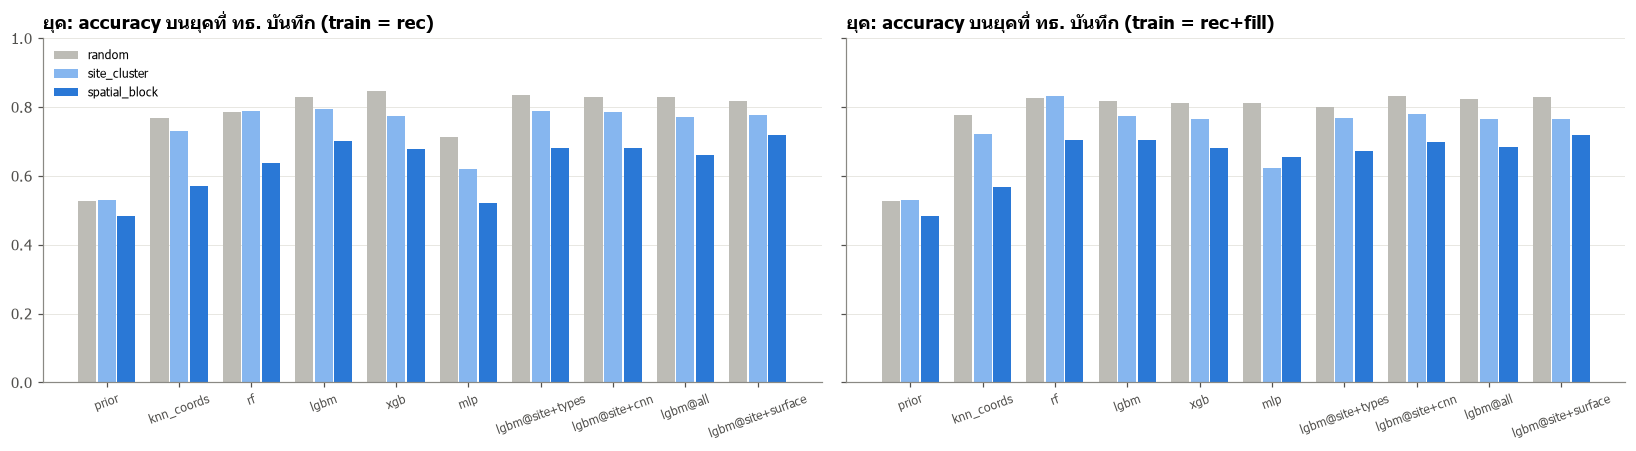

In [9]:
P_ORDER = P_MODELS + [f"lgbm@{f}" for f in P_ABL]
tP = pd.concat({(v, m): mc_table(regP[v], m, PERIODS, fl.PERIOD_ORDER, rows_mask=recorded_ids).reindex(P_ORDER) for v in regP for m in ["acc", "within1"]}, axis=1)
display(tP.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, v in zip(axes, regP):
    t = mc_table(regP[v], "acc", PERIODS, fl.PERIOD_ORDER, rows_mask=recorded_ids).reindex(P_ORDER)
    x = np.arange(len(t))
    for i, cv in enumerate(ml.CV_SCHEMES):
        ax.bar(x + (i - 1) * 0.27, t[cv], width=0.25, color=cv_color[cv], label=cv)
    ax.set_xticks(x, t.index, rotation=20, fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(f"ยุค: accuracy บนยุคที่ ทธ. บันทึก (train = {v})")
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

## 4. โมเดลตัวจริงและเติมค่าที่ขาด

- **สกุล**: สลับตามกรณี + ตัวกรองความสอดคล้อง → ทำนายตัวอย่างที่ไม่มีสกุล (top-3 + ความน่าจะเป็น) และเดาชนิด;
  feature ตามที่ตกลงหลัง notebook 15: แหล่งเดิม = `xgb` + TF-IDF ของข้อความตัวอย่าง; แหล่งใหม่ = `lgbm` ข้อมูลตัวอย่าง + หมวดหิน (notebook 07 แบบ Impute only)
  + อายุ/ชนิดหินจาก ThaiLex + WangchanBERTa (กติกาที่ตกลง: BERT ก่อน ถ้าไม่ดีกว่าใช้ multilingual — BERT ดีกว่าทั้ง acc และ top-3; ผลเทียบแบบ CV อยู่ใน notebook 15 หัวข้อ 5)
- **ยุค**: LightGBM + feature แหล่ง + ผิวดิน (`lc_`, ตกลงหลัง notebook 15) → ทำนายแหล่งที่ไม่มียุคที่บันทึก แล้วเทียบกับค่าเติมของ notebook 05
  (ค่าเติม high/medium ถูกใช้ train เมื่อเลือก `rec+fill` จึงดูความตรงกันของกลุ่ม low ที่ไม่เคยใช้ train เป็นหลัก)
- บันทึก `models/task1/final/` และ `data/processed/task1_genus_predictions.csv`, `task1_period_predictions.csv`

In [10]:
# ---- สกุล
ml.set_multiclass(len(GENERA))
# สลับตามกรณี (ตกลงกันแล้ว): แหล่งที่มีตัวอย่างระบุสกุล -> xgb ทุก feature + TF-IDF; แหล่งใหม่/ไม่เชื่อมแหล่ง -> lgbm ข้อมูลตัวอย่าง
# + หมวดหิน + ThaiLex + WangchanBERTa (feature ข้อความ fit กับข้อความของตัวอย่างที่มีสกุลเท่านั้น แบบเดียวกับ CV ใน notebook 15)
# ไฟล์ตัวจริงชื่อ genus_v7_* (v6 = รุ่นทดลอง multilingual ย้ายไป _superseded/); ผล CV ของโมเดลฐานยังอยู่ใน registry genus_v5
SITE_FM = fl.site_formation_table()
text_path = FINAL / "genus_v7_text.joblib"
# ใช้ไฟล์เดิมเฉพาะเมื่อ fingerprint (ข้อความ train + โค้ดแปลงข้อความ + embedding ของข้อความเหล่านั้น) ตรงกับปัจจุบัน
LAB_TXT = fl.specimen_text(lab)
TEXT_FP = ml.fingerprint(LAB_TXT, ml.code_hash(fl.specimen_text, fl.TextTfidf, fl.TextEmbed, fl.encode_texts), fl.text_embed(LAB_TXT, "wangchanberta"))
TEXT = ml.joblib.load(text_path) if text_path.exists() else {}
if TEXT.get("fp") != TEXT_FP:
    TEXT = {"tfidf": fl.TextTfidf().fit(LAB_TXT), "bert": fl.TextBert().fit(LAB_TXT), "fp": TEXT_FP}
    ml.joblib.dump(TEXT, text_path)


def task1_extra(d):
    # เพิ่ม tfidf_*, wangchanberta_*, fm_* ให้ตัวอย่าง (หมวดหินจากตารางแหล่งของ notebook 07; ไม่เชื่อมแหล่ง = Unknown)
    d = d.reset_index(drop=True)
    txt = fl.specimen_text(d)
    fm = [SITE_FM.FORMATION.get(int(s), "Unknown") if pd.notna(s) else "Unknown" for s in d.site_OBJECTID]
    gg = [SITE_FM.GEO_GROUP.get(int(s), "Unknown") if pd.notna(s) else "Unknown" for s in d.site_OBJECTID]
    return pd.concat([d, TEXT["tfidf"].transform(txt), TEXT["bert"].transform(txt),
                      pd.DataFrame({"fm_FORMATION": pd.Series(fm, dtype=str), "fm_GEO_GROUP": pd.Series(gg, dtype=str)}), fl.formation_features(fm)], axis=1)


TFIDF_COLS = [f"tfidf_{i}" for i in range(fl.TXT_DIM)]
BERT_COLS = [f"wangchanberta_{i}" for i in range(fl.TXT_DIM)]
FM_NUM = list(fl.formation_features(["Unknown"]).columns)
G_FINAL = {"known": ("xgb", (FS1["all"][0] + TFIDF_COLS, FS1["all"][1])),
           "new": ("lgbm", (FM_NUM + BERT_COLS, FS1["specimen"][1] + ["fm_FORMATION", "fm_GEO_GROUP"]))}
lab_x = task1_extra(lab)
g_paths = {}
for route_, (m_, fs_) in G_FINAL.items():
    g_paths[route_] = FINAL / f"genus_v7_{route_}_{m_}.joblib"
    ml.fit_final_tabular(m_, lab_x, YG, *fs_, g_paths[route_], task="multiclass", classes=GENERA)   # ใช้ไฟล์เดิมถ้า fingerprint ตรง
KNOWN_SITES = sorted(int(x) for x in lab.site_OBJECTID.dropna().unique())
GROUP_MAP = ml.genus_group_map(lab.genus_cls, lab.groups)
todo = S[S.genus_true.isna()].reset_index(drop=True)
todo_x = task1_extra(todo)
known = ml.route_known_site(todo.site_OBJECTID, KNOWN_SITES)
PG = np.where(known[:, None], ml.predict_bundle(g_paths["known"], todo_x), ml.predict_bundle(g_paths["new"], todo_x))
PG = ml.consistency_filter(PG, GENERA, todo.groups, GROUP_MAP)
order = np.argsort(-PG, axis=1)[:, :3]
nat = lab.dropna(subset=["species_true"]).groupby("genus_true").species_true.agg(lambda s: s.value_counts().idxmax())
loc = lab.dropna(subset=["species_true"]).groupby(["site_OBJECTID", "genus_true"]).species_true.agg(lambda s: s.value_counts().idxmax())
gpred = pd.DataFrame({"fossil_id": todo.fossil_id, "sci_name": todo.sci_name, "com_name": todo.com_name, "f_type": todo.f_type,
                      "site_OBJECTID": todo.site_OBJECTID, "route": np.where(known, "แหล่งเดิม (xgb + TF-IDF)", "แหล่งใหม่ (lgbm + หมวดหิน + BERT)"),
                      **{f"genus_top{i + 1}": [GENERA[o[i]] for o in order] for i in range(3)},
                      **{f"p_top{i + 1}": PG[np.arange(len(PG)), order[:, i]] for i in range(3)}})
gpred["species_guess"] = [loc.get((s, g), nat.get(g)) if g != "อื่น ๆ" else None for s, g in zip(gpred.site_OBJECTID, gpred.genus_top1)]
gpred.to_csv(ml.DATA / "processed" / "task1_genus_predictions.csv", index=False, encoding="utf-8-sig")
print(f"สกุล: ทำนาย {len(gpred):,} ตัวอย่าง | แหล่งเดิม {known.mean():.0%} | ความน่าจะเป็นอันดับ 1 เฉลี่ย {gpred.p_top1.mean():.2f} | "
      f"ทายเป็น 'อื่น ๆ' {(gpred.genus_top1 == 'อื่น ๆ').mean():.0%}")
display(gpred.groupby("genus_top1").size().sort_values(ascending=False).head(10).rename("ตัวอย่าง").to_frame().T)
# ทำไม "อื่น ๆ" เยอะ: ต่อกลุ่มซาก (fl.other_group) เทียบสัดส่วนสกุลพบน้อย (< 5 ชิ้น) ในตัวอย่างที่มีชื่อแล้ว
g_todo, g_lab = gpred.f_type.map(fl.other_group), lab.f_type.map(fl.other_group)
why = pd.DataFrame({"ต้องทำนาย": gpred.groupby(g_todo).size(), "ทายเป็น 'อื่น ๆ'": gpred.genus_top1.eq("อื่น ๆ").groupby(g_todo).mean(),
                    "'อื่น ๆ' ในตัวอย่างที่มีชื่อ": lab.genus_cls.eq("อื่น ๆ").groupby(g_lab).mean()}).sort_values("ต้องทำนาย", ascending=False)
display(why.head(14).rename_axis("กลุ่มซาก").style.format({"ต้องทำนาย": "{:,.0f}", "ทายเป็น 'อื่น ๆ'": "{:.0%}", "'อื่น ๆ' ในตัวอย่างที่มีชื่อ": "{:.0%}"}, na_rep="—"))

# ---- ยุค
ml.set_multiclass(len(PERIODS))
# ตกลงหลัง notebook 15: LightGBM + feature แหล่ง + ผิวดิน (lc_) train ด้วย rec+fill (ชุดที่วัดผลใน notebook 15: spatial_block 0.719)
# แบบ rec อย่างเดียวได้เท่ากัน (0.720) บนแหล่งที่บันทึก แต่ train ด้วยแค่ 166 แหล่ง (เพอร์เมียน 88) — ทายควอเทอร์นารีมากเกินจริง
# และตรงกับค่าเติมอิสระของ notebook 05 น้อยกว่า (ตัวเลขที่เซลล์นี้พิมพ์ท้ายสุด) จึงใช้ rec+fill ที่มีประชากรใกล้แหล่งที่ต้องเติมมากกว่า
p_model, P_FS, best_v = "lgbm", "site+surface", "rec+fill"
col = "period_rec" if best_v == "rec" else "period_train"
dP = sites[sites[col].notna()].reset_index(drop=True)
yP = dP[col].map({p: i for i, p in enumerate(PERIODS)}).values
p_path = FINAL / f"period_v5_{best_v.replace('+', '_')}_{p_model}_surface.joblib"
if p_model == "mlp":
    ml.fit_final_torch("mlp", dP, yP, p_path, task="multiclass", classes=PERIODS, num_cols=FSP[P_FS][0], cat_cols=FSP[P_FS][1], epochs=80)
else:
    ml.fit_final_tabular(p_model, dP, yP, *FSP[P_FS], p_path, task="multiclass", classes=PERIODS)
miss = sites[sites.period_rec.isna()].reset_index(drop=True)
PP = ml.predict_bundle(p_path, miss)
ppred = pd.DataFrame({"OBJECTID": miss.oid, "pred_period": [PERIODS[i] for i in PP.argmax(axis=1)], "p": PP.max(axis=1),
                      "pred_period_th": [fl.PERIOD_TH_NAME[PERIODS[i]] for i in PP.argmax(axis=1)]})
ppred = ppred.merge(fin[["OBJECTID", "PERIOD_FINAL", "final_old", "final_confidence", "final_source"]], on="OBJECTID", how="left")
ppred["agree_with_05"] = np.where(ppred.final_old.notna(), ppred.pred_period.eq(ppred.final_old), np.nan)
# ค่าเติมที่ใช้ train (เมื่อเลือก rec+fill) ไม่นับเป็นการทดสอบ; กลุ่มที่ไม่เคยใช้ train (low, 04 อย่างเดียว) เป็นการทดสอบอิสระกว่า
ppred["fill_used_in_train"] = ppred.OBJECTID.isin(fin.loc[FILL_OK, "OBJECTID"]) & (best_v == "rec+fill")
ppred.to_csv(ml.DATA / "processed" / "task1_period_predictions.csv", index=False, encoding="utf-8-sig")
print(f"ยุค: ใช้ {p_model} (train = {best_v}) | ทำนาย {len(ppred)} แหล่งที่ไม่มีบันทึก")
agree = ppred[ppred.final_old.notna()].groupby(["final_confidence", "fill_used_in_train"]).agg(
    แหล่ง=("agree_with_05", "size"), ตรงกับ_notebook05=("agree_with_05", "mean"))
display(agree.style.format({"ตรงกับ_notebook05": "{:.0%}"}))

# ตรวจทางเลือก "rec อย่างเดียว" (เหตุผลที่ไม่เลือก): train เฉพาะแหล่งที่บันทึก แล้วทายแหล่งชุดเดียวกัน
dR = sites[sites.period_rec.notna()].reset_index(drop=True)
alt_path = OUT / "checks" / "period_rec_only_lgbm_surface.joblib"
alt_path.parent.mkdir(exist_ok=True)
ml.fit_final_tabular(p_model, dR, dR.period_rec.map({p: i for i, p in enumerate(PERIODS)}).values, *FSP[P_FS], alt_path, task="multiclass", classes=PERIODS)
alt = np.array(PERIODS)[ml.predict_bundle(alt_path, miss).argmax(axis=1)]
indep = (ppred.final_old.notna() & ~ppred.OBJECTID.isin(fin.loc[FILL_OK, "OBJECTID"])).values      # ค่าเติมที่ไม่เคยใช้ train ทั้งสองแบบ
print(f"train = rec อย่างเดียว: ทายควอเทอร์นารี {int((alt == 'Quaternary').sum())} แหล่ง (มีใน train {int(dR.period_rec.eq('Quaternary').sum())} แหล่ง) "
      f"vs rec+fill {int(ppred.pred_period.eq('Quaternary').sum())} แหล่ง | ตรงกับค่าเติมอิสระ {indep.sum()} แหล่ง: "
      f"rec {np.mean(alt[indep] == ppred.final_old.values[indep]):.0%} vs rec+fill {np.mean(ppred.pred_period.values[indep] == ppred.final_old.values[indep]):.0%}")
json.dump({"genus": {"models": {r: pth.name for r, pth in g_paths.items()}, "classes": GENERA, "text": text_path.name,
                     "text_models": {"known": "tfidf (char 2-4 -> SVD 32)", "new": f"{fl.EMB_MODELS['wangchanberta']} mean pooling -> PCA 32"},
                     "formation_source": "notebook 07 sites_impute_only (by site_OBJECTID); new coordinates: DMR geology map unit",
                     "cv_reference": "notebook 15 section 5",
                     "features": {r: fs_ for r, (_, fs_) in G_FINAL.items()}, "known_sites": KNOWN_SITES,
                     "group_map": {g: sorted(c) for g, c in GROUP_MAP.items()}, "com_vocab": COM_VOCAB, "dropped_for_leak": LEAKY},
           "period": {"model": p_path.name, "variant": best_v, "classes": PERIODS, "features": FSP[P_FS]},
           "cnn_pca": pca_path.name, "type_cols": TYPE_COLS},
          open(FINAL / "final_meta.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

สกุล: ทำนาย 4,577 ตัวอย่าง | แหล่งเดิม 85% | ความน่าจะเป็นอันดับ 1 เฉลี่ย 0.75 | ทายเป็น 'อื่น ๆ' 48%


genus_top1,อื่น ๆ,Phuwiangosaurus,Isanosaurus,Stenoscisma,Kalasinemys,Fenestella,Posidonomya,Carcharhinus,Armenoceras,Thaiaspis
ตัวอย่าง,2187,1173,420,255,57,29,24,24,21,19


,ต้องทำนาย,ทายเป็น 'อื่น ๆ','อื่น ๆ' ในตัวอย่างที่มีชื่อ
กลุ่มซาก,,,
ไดโนเสาร์,"2,375",32%,2%
แบรคิโอพอด,503,27%,17%
สัตว์เลื้อยคลาน,284,69%,3%
ปลา,261,83%,5%
สัตว์เลี้ยงลูกด้วยนม,158,74%,8%
ปะการัง,138,77%,42%
หอยสองฝา,132,62%,32%
พืช,104,92%,85%
ฟอแรม / ฟิวซูลินิด,96,76%,40%


ยุค: ใช้ lgbm (train = rec+fill) | ทำนาย 352 แหล่งที่ไม่มีบันทึก


train = rec อย่างเดียว: ทายควอเทอร์นารี 33 แหล่ง (มีใน train 3 แหล่ง) vs rec+fill 5 แหล่ง | ตรงกับค่าเติมอิสระ 94 แหล่ง: rec 49% vs rec+fill 72%


## สรุป

**สกุล** (ตัวอย่างที่มีสกุล 3,944 ชิ้น → 131 สกุล + อื่น ๆ; accuracy / top-3)

| ระบบ | `random` (แหล่งเดิม) | `site_cluster` | `spatial_block` (แหล่งใหม่) |
|---|---|---|---|
| prior (ทายสกุลที่พบบ่อยสุด) | 0.169 / 0.342 | 0.075 / 0.278 | 0.036 / 0.286 |
| xgb รอบแรก (มี feature รั่ว, label ก่อนตรวจทาน) | 0.785 / 0.892 | 0.297 / 0.503 | 0.324 / 0.538 |
| xgb (ตัด feature รั่ว) | 0.661 / 0.852 | 0.265 / 0.488 | 0.275 / 0.515 |
| สลับตามกรณี + ตัวกรอง | 0.656 / 0.859 | 0.347 / 0.520 | 0.396 / 0.546 |
| **+ ข้อความ / หมวดหิน (v7, ใช้จริง; วัดใน notebook 15)** | **0.667 / 0.863** | — | **0.396 / 0.587** |

- **data leak ที่พบและแก้**: `com_name` ของตัวอย่างที่มีสกุล 33% เป็นชื่อไทยของชนิด (ชี้สกุลเดียว) แต่ตัวอย่างที่ต้องเติมชื่อมีแค่ 2%;
  `match_level` / `confidence` มาจากขั้นเชื่อมข้อมูลที่ใช้ `com_name`; `dis_name` บอกว่า "ผ่านการศึกษาแล้ว" → ตัด/แปลงแล้ว accuracy แหล่งเดิมลด 0.785 → 0.661
  (ตัวเลขเดิมสูงเกินจริง ~12 จุด); ชื่อวิทยาศาสตร์ที่เขียนไว้ใน `f_part` (9 ตัวอย่าง เช่น "Siamosaurus teeth") ถูกลบก่อนสร้าง feature ข้อความ
- **label สกุลหลังตรวจทาน**: ชื่อระดับสูงกว่าสกุลที่รูปคำเหมือนสกุล (Ruminantia 24 ตัวอย่าง, Primates, Crocodilia, Rodentia ฯลฯ) ไม่นับเป็นสกุลแล้ว
  (ย้ายไปอยู่ในชุดที่ต้องทำนาย) และแก้ชื่อสะกดผิด 9 ชื่อ (เช่น Spinomatinia → Spinomartinia); ชื่อลงท้าย -id ที่เป็นชื่อเรียกระดับวงศ์แบบไม่เป็นทางการ
  (Stegosaurid 2 ตัวอย่าง, Pectinid 1) ก็ไม่นับเป็นสกุลแล้ว — เดิมกลายเป็น "สกุล" ที่พบน้อยและไปอยู่ใน "อื่น ๆ"
- **สลับตามกรณี**: แหล่งเดิมใช้ xgb (มี feature แหล่ง), แหล่งใหม่ใช้ lgbm ข้อมูลตัวอย่างอย่างเดียว — feature แหล่งช่วยเมื่อแหล่งนั้นมีตัวอย่างระบุชื่อแล้ว
  แต่ทำให้แย่ลงที่แหล่งใหม่ (โมเดลจำว่าแหล่งไหนมีสกุลอะไร)
- **ตัวกรองความสอดคล้อง**: ในระบบที่ใช้จริงเพิ่ม accuracy ที่แหล่งใหม่ 0.342 → 0.347 และ 0.389 → 0.396; ถ้าใช้กับ xgb ตัวเดียวช่วย top-3 ที่แหล่งใหม่
  0.488 → 0.518 และ 0.515 → 0.564; ไม่มีการทายข้ามกลุ่มเหลือเลย (เดิม เช่น "ไดโนเสาร์" → เต่า, "กิ้งก่าและงู" → กวาง)
- **v7 (ตกลงหลัง notebook 15)**: แหล่งเดิม + TF-IDF ของข้อความตัวอย่าง (ดีขึ้น 5/5 fold); แหล่งใหม่ + หมวดหิน (notebook 07 แบบ Impute only) + อายุ/ชนิดหินจาก ThaiLex
  + WangchanBERTa (accuracy ไม่ดีขึ้นและผันผวนระหว่างบล็อก แต่ top-3 ดีขึ้น 0.546 → 0.587) — ตัวอย่างพิกัดใหม่ใช้หมวดหินจากแผนที่ธรณีที่ตำแหน่งนั้น;
  กติกาที่ตกลง "ลอง BERT ก่อน ถ้าไม่ดีกว่าใช้ multilingual": หลังแก้บั๊ก embedding ใน notebook 15 แล้ว BERT ดีกว่า multilingual ทั้ง acc และ top-3 (0.391 / 0.576)
  จึงใช้ BERT (v6 ที่ลอง multilingual ย้ายไป `_superseded/`)
- **ชนิด** (P(สกุล) × สัดส่วนชนิดในแหล่ง/ทั้งประเทศ): 0.672 แหล่งเดิม, 0.436–0.451 แหล่งใหม่ (วัดกับ 2,685 ตัวอย่างที่ระบุชนิด)
- **เติมชื่อ 4,577 ตัวอย่าง** (`data/processed/task1_genus_predictions.csv`): 85% อยู่แหล่งเดิม; 48% ทายเป็น "อื่น ๆ" — มาจากข้อมูล ไม่ใช่โมเดลผิด:
  กลุ่มที่แทบไม่มีสกุลครบ 5 ชิ้น (เอไคโนเดิร์ม / ครัสตาเชียน 100%, พืช / หอยฝาเดียว 92%) และแหล่งที่มีแต่สกุลพบน้อย
  (ไดโนเสาร์ที่ต้องทำนาย 32% ทั้งที่ในตัวอย่างที่มีชื่อมีแค่ 2%) — ควรใช้เป็น "ข้อเสนอให้ผู้เชี่ยวชาญตรวจ" ไม่ใช่ชื่อสุดท้าย

**ยุค** (แหล่ง; วัดเฉพาะ 166 แหล่งที่ ทธ. บันทึก; LightGBM)

| train / feature | `random` | `site_cluster` | `spatial_block` | คลาดไม่เกิน 1 ยุค (`spatial_block`) |
|---|---|---|---|---|
| prior | 0.527 | 0.531 | 0.484 | 0.760 |
| kNN บนพิกัด (rec+fill) | 0.777 | 0.721 | 0.567 | 0.732 |
| `rec` (ยุคที่บันทึกอย่างเดียว), feature แหล่ง | 0.828 | 0.794 | 0.701 | 0.878 |
| `rec+fill` (+ ค่าเติมที่มี PBDB รองรับ), feature แหล่ง | 0.817 | 0.775 | 0.704 | 0.906 |
| **`rec+fill` + ผิวดิน (`lc_`, ใช้จริง; ตกลงหลัง notebook 15)** | **0.830** | **0.764** | **0.719** | **0.900** |

- **แก้การรั่วหลังตรวจทาน**: notebook 04 เติมยุคโดยอ้างอิงยุคที่ ทธ. บันทึกของแหล่งอื่น (สกุลเดียวกัน) → ค่าเติมที่มาจาก 04 อย่างเดียว (28 แหล่ง)
  พาคำตอบของแหล่งทดสอบเข้า train — ตัดออกแล้วประโยชน์ของค่าเติมเหลือแค่ +0.003 (รอบก่อน +0.025 ส่วนใหญ่จึงมาจากการรั่ว)
- `rec` + ผิวดิน ได้เท่ากันบนแหล่งที่บันทึก (0.720) แต่ทายควอเทอร์นารี 33 แหล่งจาก train แค่ 3 แหล่ง (`rec+fill`: 5)
  และตรงกับค่าเติมอิสระ 94 แหล่งแค่ 49% (`rec+fill` 72%; คำนวณในหัวข้อ 4) → ใช้ `rec+fill`
- เพิ่มประเภทซากในแหล่ง / CNN embedding ไม่ช่วย (0.673–0.697) และเสี่ยงรั่ว → ไม่ใช้
- **เติมยุค 352 แหล่ง** (`data/processed/task1_period_predictions.csv`): ตรงกับค่าเติมของ notebook 05 ที่ไม่เคยใช้ train —
  ระดับ low 76%, ระดับ medium ที่มาจาก 04 อย่างเดียว 64%; ค่าเติมที่ใช้ train ตรง 100% (ไม่นับเป็นการทดสอบ)
- **notebook 05 เพิ่มกฎตรวจยุคกับซากในแหล่ง** (เช่น รอยตีนไดโนเสาร์ลำน้ำหมันแดง: เพอร์เมียน → ครีเทเชียส) ค่าเติมที่ใช้ train จึงเพิ่ม 1 แหล่ง

**โมเดลตัวจริง** (`models/task1/final/`): `genus_v7_known_xgb.joblib`, `genus_v7_new_lgbm.joblib`, `genus_v7_text.joblib` (TF-IDF + BERT PCA),
`period_v5_rec_fill_lgbm_surface.joblib`, `cnn_pca.joblib` และ `final_meta.json` (คลาส, feature, รายชื่อแหล่งเดิม, mapping สกุล → กลุ่มซาก,
คำศัพท์ `com_name` ทั่วไป) — รุ่นก่อนแก้ย้ายไป `_superseded/`